This sample code uses the cv2 package for image interpretation. Specifically, we want to extract individual cells from a grid in an image. 


As written, this is incomplete. Here are a few issues:

1) cells that are the wrong shape to be grades should be discarded
2) cells that are the right shape need to be trimmed to all be exactly the same shape; there is a bit of variation in size
3) cells that are too blank should be discarded; the darkness variable can help discern this


After you've got that done:

Get the resulting images to be saved to individual files, all of the exact same shape. It might be nice to preserve the original unique identifier
in the filename, but add on an integer to disambiguate which grade it is. Put all the resulting image files into a single folder. Some images will still be bogus, but that's OK at this point.





In [1]:
!pip install opencv-python


   ---------------------------------------- 0.0/48.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.0 MB ? eta -:--:--
   - -------------------------------------- 1.6/48.0 MB 8.4 MB/s eta 0:00:06
   - -------------------------------------- 2.1/48.0 MB 6.3 MB/s eta 0:00:08
   -- ------------------------------------- 3.1/48.0 MB 5.7 MB/s eta 0:00:08
   ---- ----------------------------------- 5.0/48.0 MB 5.7 MB/s eta 0:00:08
   ------ --------------------------------- 7.6/48.0 MB 6.9 MB/s eta 0:00:06
   -------- ------------------------------- 10.0/48.0 MB 7.7 MB/s eta 0:00:05
   --------- ------------------------------ 11.5/48.0 MB 7.7 MB/s eta 0:00:05
   ---------- ----------------------------- 12.6/48.0 MB 7.4 MB/s eta 0:00:05
   ---------- ----------------------------- 13.1/48.0 MB 6.9 MB/s eta 0:00:06
   ----------- ---------------------------- 13.4/48.0 MB 6.5 MB/s eta 0:00:06
   ----------- 


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
import PIL.Image as Image
from pathlib import Path

In [3]:


def find_grid(path, min_frac=0.5): #main function that detects the grid  
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    #crop off the top and bottom ##### 
    img = img[100:-200,100:-200]
    # plt.figure(figsize=(12, 16)) #turn these on if you want to see the images after cropping
    # plt.imshow(img, cmap='gray')
    # plt.show()
    
    bw = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                               cv2.THRESH_BINARY_INV, 31, 15)

    H, W = img.shape
    h_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (W // 30, 1))
    v_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (1, H // 30))
    h_mask = cv2.morphologyEx(bw, cv2.MORPH_OPEN, h_kernel)
    v_mask = cv2.morphologyEx(bw, cv2.MORPH_OPEN, v_kernel)

    def positions(mask, axis, length):
        sums = mask.sum(axis=axis) / 255
        idx = np.where(sums > length * min_frac)[0]
        groups = np.split(idx, np.where(np.diff(idx) > 3)[0] + 1)
        return [int(g.mean()) for g in groups if len(g)]

    ys = positions(h_mask, 1, W)   # horizontal line y-positions
    xs = positions(v_mask, 0, H)   # vertical line x-positions

    v_mask, xs = find_vertical(bw, img.shape[0]) # finds the single vertical lines and corrects for double lines
    h_mask, ys = find_horizontal(bw, bw.shape[1], cover=0.2) # corrects horizontal lines 

    # Mask of the grid lines (slightly dilated so no remnants are left)
    line_mask = cv2.dilate(cv2.bitwise_or(h_mask, v_mask), np.ones((3, 3), np.uint8))

    # Binary version (what you had before), used for the darkness metric
    clean = cv2.subtract(bw, line_mask)

    # Grayscale version: paint the grid lines out of the original gray image
    clean_gray = img.copy()
    clean_gray[line_mask > 0] = 255        # option 1: paint lines white (simple, fast)
    # clean_gray = cv2.inpaint(img, line_mask, 3, cv2.INPAINT_TELEA)   # option 2: fills in using neighboring pixels, usually looks better where strokes cross a line

    pad = 2
    cells = {}
    for r in range(1, len(ys) - 3):
        for c in range(len(xs) - 1):
            sl = (slice(ys[r] + pad, ys[r + 1] - pad),
                  slice(xs[c] + pad, xs[c + 1] - pad))
            cells[(r, c)] = clean[sl]

    pad_gray = 4   # skip the line remnants at the cell edges
    cells_gray = {}
    for r in range(1, len(ys) - 3):
        for c in range(len(xs) - 1):
            cells_gray[(r, c)] = img[ys[r] + pad_gray : ys[r + 1] - pad_gray,
                                 xs[c] + pad_gray : xs[c + 1] - pad_gray]

    return img, bw, h_mask, v_mask, xs, ys, cells, cells_gray

def find_vertical(bw, H, gap=8, cover=0.25): #helper functions for find_grid
    # Fuse double lines: close horizontally by about the gap between the pair
    k_close = cv2.getStructuringElement(cv2.MORPH_RECT, (gap, 1))
    fused = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, k_close)

    # Keep only long vertical runs
    k_open = cv2.getStructuringElement(cv2.MORPH_RECT, (1, H // 40))
    v_mask = cv2.morphologyEx(fused, cv2.MORPH_OPEN, k_open)

    # Per-column coverage as a fraction of page height (0..1)
    prof = (v_mask > 0).sum(axis=0) / H

    # Absolute threshold, so line weight doesn't matter 
    cols = np.where(prof > cover)[0]
    groups = np.split(cols, np.where(np.diff(cols) > 1)[0] + 1)
    xs = [int(g.mean()) for g in groups if len(g)]
    return v_mask, xs

def find_horizontal(bw, W, gap=1, cover=0.25, open_div=40):
    # Optional: fuse double/thick horizontal lines (raise gap if needed)
    k_close = cv2.getStructuringElement(cv2.MORPH_RECT, (1, gap))
    fused = cv2.morphologyEx(bw, cv2.MORPH_CLOSE, k_close)

    # Keep only long horizontal runs
    k_open = cv2.getStructuringElement(cv2.MORPH_RECT, (W // open_div, 1))
    h_mask = cv2.morphologyEx(fused, cv2.MORPH_OPEN, k_open)

    prof = (h_mask > 0).sum(axis=1) / W
    rows = np.where(prof > cover)[0]
    groups = np.split(rows, np.where(np.diff(rows) > 1)[0] + 1)
    ys = [int(g.mean()) for g in groups if len(g)]
    return h_mask, ys

['aybvchqzw.tif', 'bzbsduogl.tif', 'eskjztton.tif', 'fwrholjhq.tif', 'ibknzggjz.tif', 'xfeqbnlzh.tif']
xs: [8, 133, 260, 388, 523, 650, 775, 906, 1042, 1181, 1318, 1458]
ys: [125, 134, 233, 332, 431, 530, 630, 729, 828, 927, 1026]
Shape of cell =  (91, 117)
Shape of cell =  (91, 117)
Shape of cell =  (91, 117)
Shape of cell =  (91, 117)
Shape of cell =  (92, 117)
Shape of cell =  (91, 117)
Shape of cell =  (91, 117)


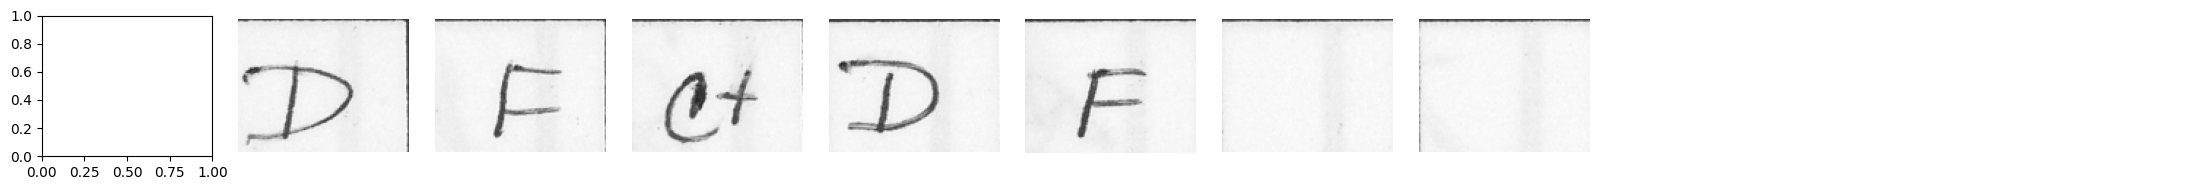

Cell darkness: 0.0479
Cell darkness: 0.0317
Cell darkness: 0.0557
Cell darkness: 0.0452
Cell darkness: 0.0441
Cell darkness: 0.0003
Cell darkness: 0.0001
xs: [328, 466, 591, 718, 846, 981, 1106, 1231, 1362, 1499, 1638, 1776]
ys: [114, 122, 221, 321, 420, 519, 618, 717, 816, 915, 1014]
Shape of cell =  (91, 130)
Shape of cell =  (92, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)


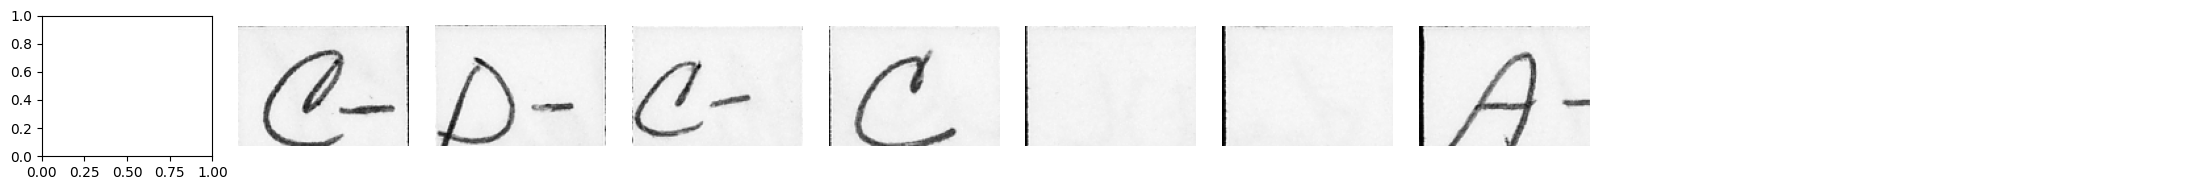

Cell darkness: 0.1035
Cell darkness: 0.0681
Cell darkness: 0.0609
Cell darkness: 0.0751
Cell darkness: 0.0001
Cell darkness: 0.0000
Cell darkness: 0.0730
xs: [9, 134, 261, 389, 524, 651, 777, 907, 1043, 1182, 1319, 1459]
ys: [112, 121, 220, 320, 419, 518, 617, 717, 816, 915, 1014]
Shape of cell =  (91, 117)
Shape of cell =  (92, 117)
Shape of cell =  (91, 117)
Shape of cell =  (91, 117)
Shape of cell =  (91, 117)
Shape of cell =  (92, 117)
Shape of cell =  (91, 117)


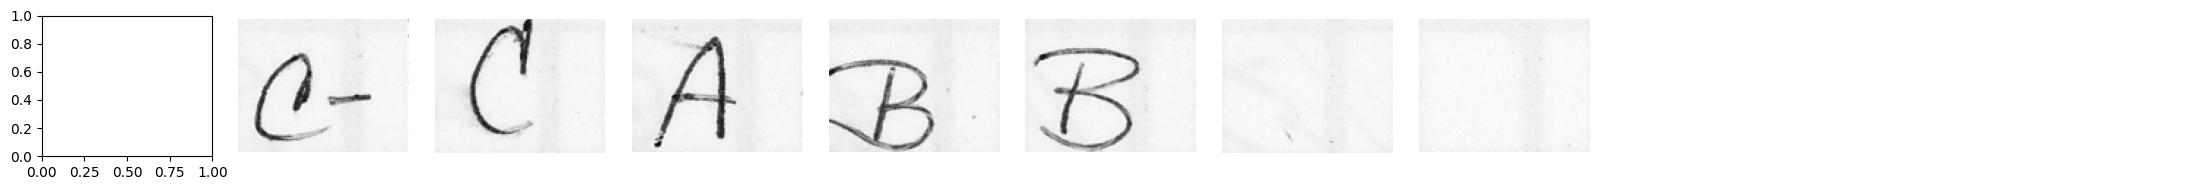

Cell darkness: 0.0592
Cell darkness: 0.0392
Cell darkness: 0.0485
Cell darkness: 0.0886
Cell darkness: 0.0776
Cell darkness: 0.0017
Cell darkness: 0.0007
xs: [331, 469, 593, 721, 848, 983, 1108, 1234, 1364, 1502, 1641, 1779]
ys: [119, 127, 226, 326, 425, 524, 623, 722, 821, 920, 1019]
Shape of cell =  (91, 130)
Shape of cell =  (92, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)


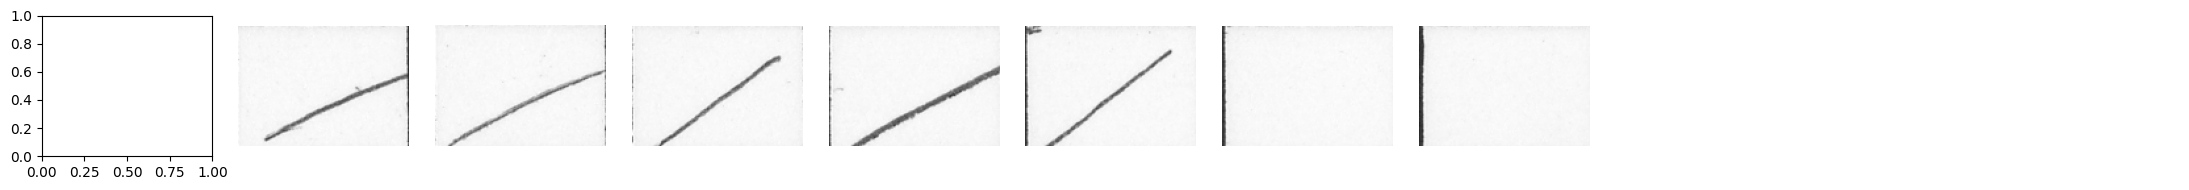

Cell darkness: 0.0377
Cell darkness: 0.0364
Cell darkness: 0.0341
Cell darkness: 0.0486
Cell darkness: 0.0349
Cell darkness: 0.0001
Cell darkness: 0.0002
xs: [329, 467, 591, 718, 846, 981, 1106, 1232, 1362, 1500, 1639, 1777]
ys: [115, 124, 223, 322, 421, 520, 619, 718, 817, 916, 1015]
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)


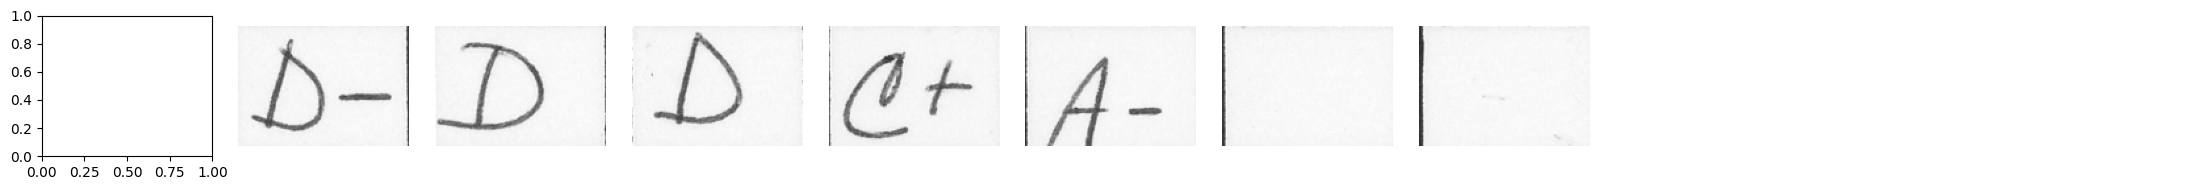

Cell darkness: 0.0672
Cell darkness: 0.0513
Cell darkness: 0.0629
Cell darkness: 0.0804
Cell darkness: 0.0624
Cell darkness: 0.0002
Cell darkness: 0.0010
xs: [329, 467, 591, 719, 847, 981, 1107, 1232, 1362, 1500, 1639, 1777]
ys: [114, 122, 221, 321, 420, 519, 618, 717, 816, 915, 1014]
Shape of cell =  (91, 130)
Shape of cell =  (92, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)
Shape of cell =  (91, 130)


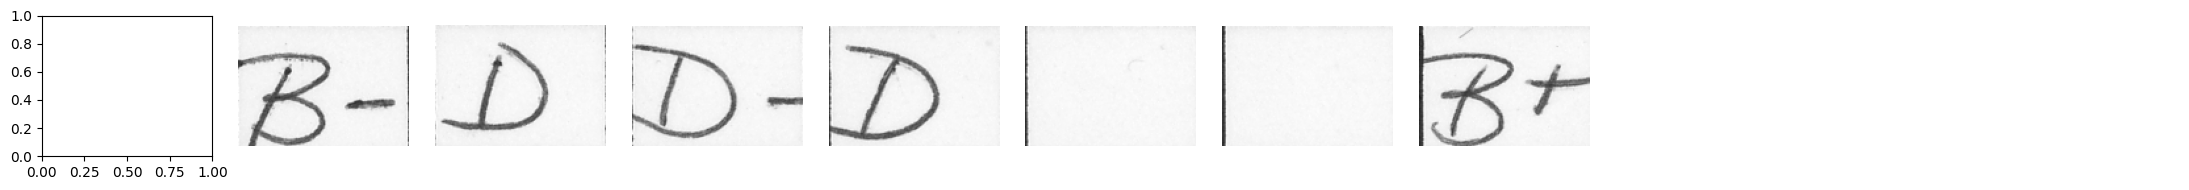

Cell darkness: 0.1045
Cell darkness: 0.0542
Cell darkness: 0.0893
Cell darkness: 0.0791
Cell darkness: 0.0006
Cell darkness: 0.0000
Cell darkness: 0.0983


In [4]:
directory = "./selected_anon_images/images1973"

def get_letters(fname):
    
    path_name=os.path.join(directory,fname)
    darknesses = []
    img, bw, h_mask, v_mask, xs, ys, cells, cells_gray =find_grid(path_name)
    print(f"xs: {xs}")
    print(f"ys: {ys}")  
    c = 0 #final grades, or sometimes semester grades 
    n_cols = len(xs) - 1
    nrows = 1
    fig, axes = plt.subplots(1, n_cols, figsize=(2 * n_cols, 2 * nrows))
    axes = axes.ravel()
    for r in range(1, len(ys) - 3):
        print("Shape of cell = ", cells_gray[(r, c)].shape)
        axes[r].imshow(cells_gray[(r, c)], cmap='gray', vmin=0, vmax=255)
        axes[r].axis('off')
        darknesses.append(np.sum(cells[(r, c)] > 0) / cells[(r, c)].size)
    for ax in axes[6:]:
        ax.axis('off')   # hide unused slots
    plt.tight_layout()
    plt.show()
    return img, bw, xs, ys, cells, cells_gray, darknesses

# Get only files (ignores subdirectories)
filenames = [f for f in os.listdir(directory) if os.path.isfile(os.path.join(directory, f))]
print(filenames)
for fname in filenames:
    img, bw, xs, ys, cells, cells_gray, darknesses = get_letters(fname)
    for darkness in darknesses:
        print(f"Cell darkness: {darkness:.4f}")

First we wanted to define the numberic contraints on each cell that we would like to keep versus thow away for size and darkness. 

Starting with darkness, I would like to thow away cells with no iformation in them, these cells would have a lower darkness than those with written information in them. The grey area with empty cells are the cells with lightly written grades. We took a look at some of the gradsheet images manually and found cells with no information had a darkness of less than 0.0000, but some of the slicing included the lines either making the cell borders or lines striking through which added to the cell darkenss so we couldn't just use 0 for the contraint. Next, I compared against the lighter written grades. Looking at 10 or so lightly written grades, they averaged a darkness of around 0.05. To ensure that we are not throwing away actual grades but removing as many blank cells as possible, we determined a darkness of less than 0.01 to be our threshold for cells that are "too light" and should be thrown away. After testing, if it is discovered that this values is too low, it can be increased but to a value no greater than about 0.03.

Similarly, there were some cells that had information scribbled out or was just too dark to be legible. Looking at these scribbles, it was discovered that most of them had a darkness around the same as a normally written grade, so those could not be filtered out using darkness without removing a majority of our viable information. Certain cells that did have an excessive amount of scibbles were sitting above a 0.1. Giving a small buffer, we determined a darkness of above 0.12 to be our thrshold for cells that are "too dark" and should be thrown away. This value could be slightly reduced to grab even more cells but should go no lower than 0.1. 

Next, the size of the cell must be evaluated. Technically, all the cells should be the same height and width because each sheet is the same, however, this is not always the case because of human markings on the sheet and computer slicing of the cells. In some cases, a teacher may have written a horizontal line through a cell to denote the student does not have a grade for that class. However, these markings are then read in by the computer as new rows. Looking at a couple regular gradesheets, the cells are around (91, 123) with around a 5ish unit error accounting for some smaller columns. Given that a teacher would only strike through a cell horizontally or diagonally, the width of a column would not be affected by the indication of no information, therefore we say that width does not effect whether or not we keep the cell. Since the height ranges around 90 units the threshold for max height has been set at 80 units. This threshold should exceed 85.

final contraints for what to throw away: <br>
-too light: darkness is less than 0.01 <br>
-too dark: darkness is more than 0.12 <br>
-too small: height = less than 80


In [8]:
# what grid positions did it find
print(xs)
print(ys)

[330, 468, 592, 719, 847, 982, 1107, 1232, 1363, 1501, 1639, 1777]
[115, 123, 222, 322, 421, 520, 619, 718, 774, 817, 916, 1015]


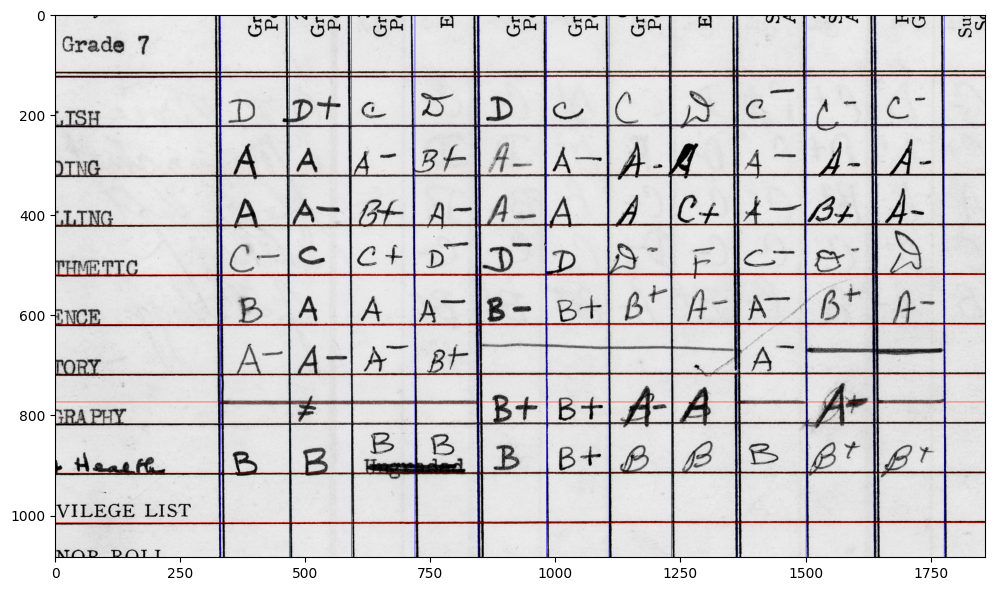

12 vertical lines, 12 horizontal lines


In [9]:

# Check the overlay to make sure the grid is correctly detected. convert to color so the lines show up in red/blue
overlay = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)

H, W = img.shape

for y in ys:
    cv2.line(overlay, (0, y), (W - 1, y), (0, 0, 255), 1)   # horizontal = red
for x in xs:
    cv2.line(overlay, (x, 0), (x, H - 1), (255, 0, 0), 1)   # vertical = blue

plt.figure(figsize=(12, 16))
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.show()
print(f"{len(xs)} vertical lines, {len(ys)} horizontal lines")


note: Gemini was used for certain parts of the code (eg how to impement iterdr)

function to iterate through all files <br>
-gets the square <br>
-check to make sure it meets size and darkness constraint <br>
-if yes, call save image

save image helper function

In [7]:
def darkness_pass(darkness):
    if darkness < 0.01:
        return False
    if darkness > 0.12:
        return False
    return True
def size_pass(shape):
    x = shape[0]
    if x < 80:
        return False
    return True
def get_letters2(fname, directory):
    path_name=os.path.join(directory,fname)
    darknesses = []
    shapes = []
    keys_list = []
    img, bw, h_mask, v_mask, xs, ys, cells, cells_gray = find_grid(path_name)
    for c in range(11):
        n_cols = len(xs) - 1
        nrows = 1
        for r in range(1, len(ys) - 3):
            s = cells_gray[(r, c)].shape
            d = np.sum(cells[(r, c)] > 0) / cells[(r, c)].size
            if (darkness_pass(d) and size_pass(s)):
                shapes.append(s)
                darknesses.append(d)
                keys_list.append((r,c))
    return img, bw, xs, ys, cells, cells_gray, darknesses, shapes, keys_list
def resize_cells(cells_gray, key, ys, crop_margin = 4):
    cell = cells_gray[key]
    cell_array = np.array(cell[:, crop_margin:-crop_margin])
    cell_array = Image.fromarray(cell_array)
    cell_array = cell_array.resize((28, 28))
    cells_gray[key]  = cell_array
    return cells_gray
def save_img(cells_gray, key, ys, count, src_filename, out_dir):
    cells_gray = resize_cells(cells_gray, key, ys, crop_margin = 4)
    img = cells_gray[key]
    unique_id = src_filename[0:8]
    f = unique_id + str(count) + ".png"
    img.save(os.path.join(out_dir, f))
    return

root_dir = Path("./selected_anon_images")
image_extensions = {".tif"}
sub_dir = []

for img_dir in root_dir.iterdir():
    #sub_dir.append(images)
    filenames = [f for f in os.listdir(img_dir) if os.path.isfile(os.path.join(img_dir, f))]
    for fname in filenames:
        img, bw, xs, ys, cells, cells_gray, darknesses, shapes, keys_list = get_letters2(fname, img_dir)
        count_keep = 0
        count_throw = 0
        for key in cells_gray:
            if key in keys_list:
                count_keep += 1
                save_img(cells_gray, key, ys, count_keep, fname, out_dir="./keep")
            else:
                count_throw += 1
                save_img(cells_gray, key, ys, count_throw, fname, out_dir="./throw_away")




C:\Users\kaili\AppData\Local\Temp\ipykernel_18784\3455726241.py:23: RuntimeWarning: invalid value encountered in scalar divide
  d = np.sum(cells[(r, c)] > 0) / cells[(r, c)].size


Final results

Kept 2415 cells, example images added in the keep folder. Lots of cells with correct grades, still have some cells with just lines through them. This could be solved by increasing the minimum darkness but would have to be done carefully as to not throw away too many grades. 

Throw away 1504 cells, example images in the throw away folder. Lots of empty cells, some contain grades (would have to go through at each step or file to see why this happened). 

In the future I would check the thrown away cells and see why they were thrown away to see if there are critera that need to be changed or filters that are not working correctly. Then I would also implement smart cropping for the kept cells. 